In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchdiffeq import odeint
import sklearn.datasets as skld


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


We start by constructing the velocity field with conditional probability path.

In [7]:
# get velocity field u_t(x|x_1)
def conditional_field(position, time, target, sigmin):
    return (target-(1-sigmin)*position)/(1-(1-sigmin)*time)

# get flow psi_t(x)
def conditional_sample(noise, time, target, sigmin):
    sigma = 1-(1-sigmin)*time
    mean = time*target
    return sigma*noise + mean

## 1-D Flow Matching


In [ ]:
Sigmin = 0.01 # sigma_min

### Visualization of a conditional field in 1D

Let's see how a conditional field with one target looks like:

(-1.0, 1.0)

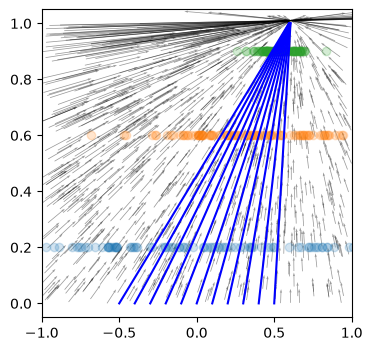

In [ ]:
Target = 0.6 # x_1 for conditional FM

# get random coordinates of the velocity field
def get_batch(N=1000):
    positions = np.random.uniform(-1, 1, N)
    times = np.random.uniform(0, 1, N)
    xt = np.column_stack([positions, times])
    return xt

# generate coordinates of the velocity field
xt = get_batch(1000)
target = np.full_like(xt[:,0], Target) # generate a list of the same target
field_test = conditional_field(xt[:,0], xt[:,1], target, Sigmin) # construct a cond field
plt.quiver(xt[:,0], xt[:,1], field_test, np.ones_like(field_test), angles='xy', scale_units = 'xy', scale = 20, alpha = 0.4)

# calculate examples of cond probability paths with odeint
tint = np.linspace(0.0,1.0)
xint = odeint(lambda t, x:conditional_field(x, t, Target, Sigmin), torch.tensor(np.linspace(-0.5,0.5,11).reshape(-1, 1)), torch.tensor(tint))
xint, tint = np.broadcast_arrays(xint, tint.reshape(-1,1,1)) # broadcasting extends tint from (50,1,1) to (50,11,1), matching xint
plt.plot(xint[...,0], tint[...,0], c='b') # plot cond prob paths

# draw samples at different times
noise = torch.randn(100)
for t in [0.2, 0.6, 0.9]:
    sample = conditional_sample(noise, t, Target, Sigmin)
    plt.scatter(sample, np.full_like(sample, t), alpha=0.2)

plt.gcf().set_size_inches(4,4)
plt.xlim(-1, 1)

### Training

In [70]:
def sample_data(N=100):
    return torch.tensor(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=N),
                                          scale=0.1), device=device)

def mlp(hidden=128):
    return torch.nn.Sequential(
        torch.nn.Linear(2,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,1)
    ).to(device)

def train(model:torch.nn.Sequential):
    opt = torch.optim.Adam(model.parameters(), 1e-3)

    for i in range(10000):
        batch_size = 1000

        target = sample_data(batch_size)
        times = torch.rand(batch_size, device=device)
        positions = conditional_sample(torch.randn(batch_size, device=device), times, target, Sigmin)
        xt = torch.column_stack([positions, times])

        model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]
        cond_field = torch.tensor(conditional_field(xt[:,0], xt[:,1], target, Sigmin), dtype=torch.float32)
        loss = torch.nn.functional.mse_loss(model_field, cond_field)        
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % 1000 == 0:
            xt_np = xt.detach().cpu().numpy()
            cond_field_np = cond_field.detach().cpu().numpy()
            model_field_np = model_field.detach().cpu().numpy()
            plt.quiver(xt_np[:,0],xt_np[:,1], cond_field_np,np.ones_like(cond_field_np), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'black')
            plt.quiver(xt_np[:,0],xt_np[:,1], model_field_np,np.ones_like(model_field_np), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'maroon')
            plt.gcf().set_size_inches(4,4)
            plt.xlim(-1,1)
            plt.show()
    return model


/tmp/ipykernel_3783801/1724711084.py:25: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]
/tmp/ipykernel_3783801/1724711084.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  cond_field = torch.tensor(conditional_field(xt[:,0], xt[:,1], target, Sigmin), dtype=torch.float32)


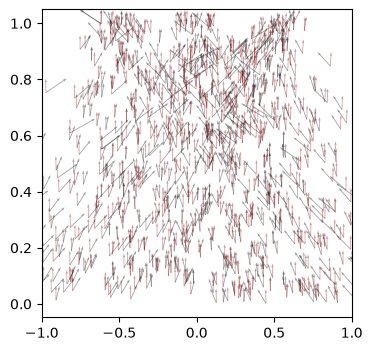

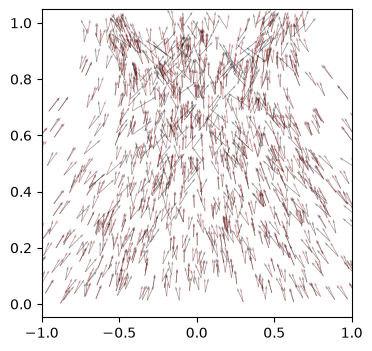

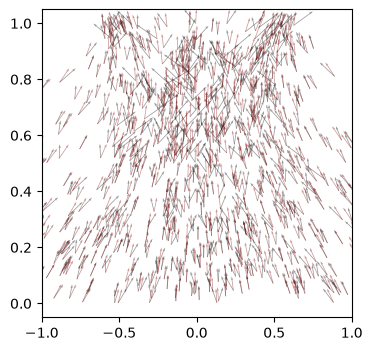

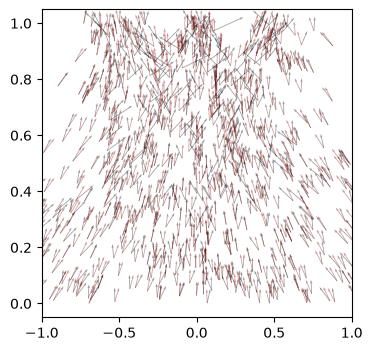

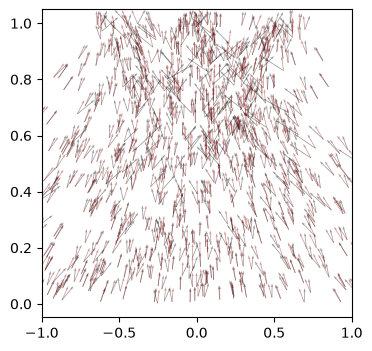

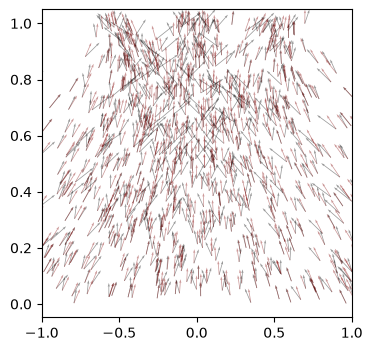

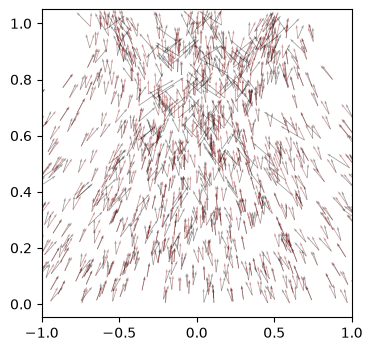

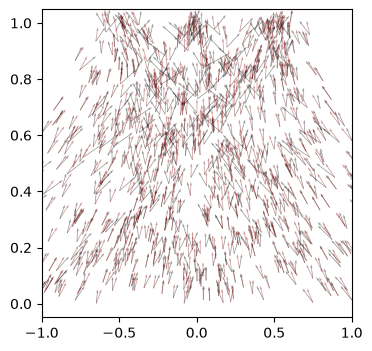

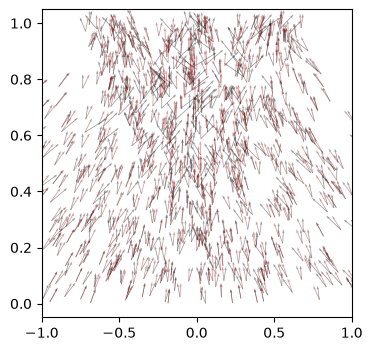

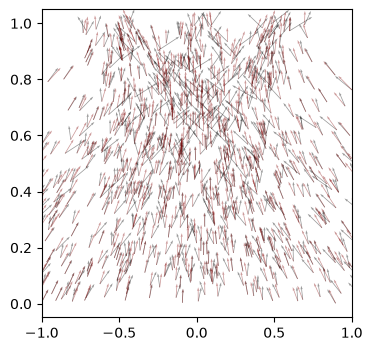

In [71]:
model = mlp()

model = model.train()
model = train(model)

### Model Evaluaion

In [72]:
model = model.eval()

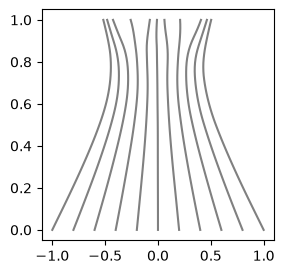

In [75]:
with torch.no_grad():
    tint = np.linspace(0.0,1.0)
    xint = odeint(lambda t, x:model(torch.cat([x,torch.full(x.shape, t.item(), device=device)], dim=-1).float()),
                torch.tensor(np.linspace(-1,1,11).reshape(-1, 1), device=device), torch.tensor(tint, device=device))
    xint, tint = np.broadcast_arrays(xint.detach().cpu().numpy(), tint.reshape(-1,1,1))
    plt.plot(xint[...,0], tint[...,0], c='grey')
    plt.gcf().set_size_inches(3,3)

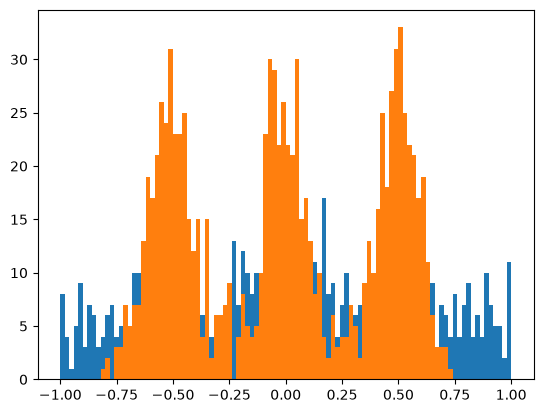

In [76]:
with torch.no_grad():
    tint = torch.tensor([0.0,1.0], dtype=torch.float32, device=device)
    noise = torch.randn(1000,1, device=device)
    xint = odeint(lambda t,x: model(torch.cat([x,torch.full(x.shape, t.item(), device=device)],dim=-1).float()).detach(), noise, tint)
    bins = np.linspace(-1,1,101)
    plt.hist(xint[0,::,-1].detach().cpu().numpy(), bins = bins)
    plt.hist(xint[-1,::,-1].detach().cpu().numpy(), bins = bins)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,
         1.,  5.,  6.,  9.,  7.,  9., 13., 12., 24., 20., 23., 29., 26.,
        14., 18., 21., 17., 21., 11., 16.,  7.,  1.,  3.,  0.,  4.,  4.,
         2.,  4.,  6.,  7., 12.,  9., 16., 24., 24., 37., 37., 22., 29.,
        28., 26., 18., 11., 13., 10.,  6.,  5.,  3.,  2.,  2.,  3.,  1.,
         7.,  5.,  8., 10., 11., 10., 27., 22., 17., 32., 30., 19., 26.,
        22., 19., 14., 14., 14.,  4.,  5.,  2.,  0.,  0.,  1.,  0.,  0.,
         1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]),
 array([-1.  , -0.98, -0.96, -0.94, -0.92, -0.9 , -0.88, -0.86, -0.84,
        -0.82, -0.8 , -0.78, -0.76, -0.74, -0.72, -0.7 , -0.68, -0.66,
        -0.64, -0.62, -0.6 , -0.58, -0.56, -0.54, -0.52, -0.5 , -0.48,
        -0.46, -0.44, -0.42, -0.4 , -0.38, -0.36, -0.34, -0.32, -0.3 ,
        -0.28, -0.26, -0.24, -0.22, -0.2 , -0.18, -0.16, -0.14, -0.12,
        -0.1 , -0.08, -0.06, -0.04, -0.02,  0.  ,  0.02,  0.04,  0.06,
        

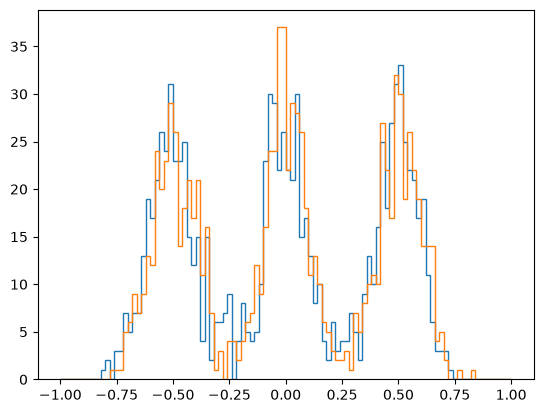

In [77]:
plt.hist(xint[-1,::,-1].detach().cpu().numpy(), bins = bins, histtype = 'step')
plt.hist(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=1000), scale=0.1), bins = bins, histtype='step')


In [78]:
print("Model:", next(model.parameters()).device)
print("CUDA memory allocated:",
      torch.cuda.memory_allocated() / 1024**2, "MB")

Model: cuda:0
CUDA memory allocated: 16.861328125 MB


## 2-D FLow Matching

In [36]:
Sigmin_2d = torch.tensor([0.01, 0.01], device=device)

In [79]:
def sample_data_2d(N=100):
    return torch.tensor(skld.make_moons(N)[0], device=device)

def mlp_2d(hidden=128):
    return torch.nn.Sequential(
        torch.nn.Linear(3,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,2)
    ).to(device)

def train_2d(model:torch.nn.Sequential):
    opt = torch.optim.Adam(model.parameters(), 1e-3)

    for i in range(20000):
        batch_size = 1000

        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        positions = conditional_sample(torch.randn(batch_size, 2, device=device), times, target, Sigmin_2d)
        xt = torch.column_stack([positions, times])

        model_field = model(torch.tensor(xt, dtype=torch.float32))
        cond_field = torch.tensor(conditional_field(xt[:,:-1], xt[:,-1:], target, Sigmin_2d), dtype=torch.float32)
        loss = torch.nn.functional.mse_loss(model_field, cond_field)
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % 1000 == 0:
            print(i, float(loss))
    return model


In [80]:
model_2d = mlp_2d()

model_2d.train()
model_2d = train_2d(model_2d)

/tmp/ipykernel_3783801/986657340.py:24: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  model_field = model(torch.tensor(xt, dtype=torch.float32))
/tmp/ipykernel_3783801/986657340.py:25: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  cond_field = torch.tensor(conditional_field(xt[:,:-1], xt[:,-1:], target, Sigmin_2d), dtype=torch.float32)


0 1.559812307357788
1000 0.9116320013999939
2000 0.9127938747406006
3000 0.9002065658569336
4000 0.9000170230865479
5000 0.8981615900993347
6000 0.9280571937561035
7000 0.9174250960350037
8000 0.8520398736000061
9000 0.8866650462150574
10000 0.9309269189834595
11000 0.8468833565711975
12000 0.9292779564857483
13000 0.9356738924980164
14000 0.9196141958236694
15000 0.8960697650909424
16000 0.9204074144363403
17000 0.8710303902626038
18000 0.8893657922744751
19000 0.9290131330490112


In [85]:
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    xint = odeint(lambda t, x:model_2d(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)),
                torch.tensor(torch.randn(1000,2), device=device), torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

/tmp/ipykernel_3783801/1795906032.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(torch.randn(1000,2), device=device), torch.tensor(tint, device=device))


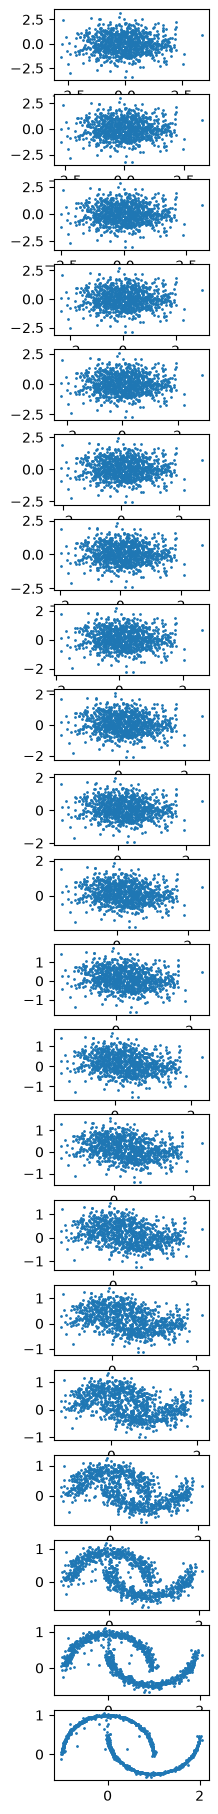

In [90]:
f, axarr = plt.subplots(21,1)
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
f.set_size_inches(2,23)

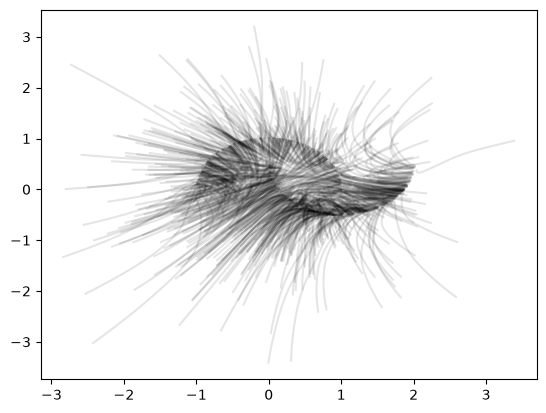

In [91]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)

## Transformer FM